In [1]:
import os, urllib.request, zipfile
os.makedirs('../data', exist_ok=True)
if not os.path.exists('../data/hymenoptera_data'):
    urllib.request.urlretrieve('https://download.pytorch.org/tutorial/hymenoptera_data.zip',
                               '../data/hymenoptera_data.zip')
    zipfile.ZipFile('../data/hymenoptera_data.zip').extractall('../data')
print(os.listdir('../data/hymenoptera_data'))   # expect ['train', 'val']

['train', 'val']


In [2]:
import copy, torch, torch.nn as nn, torch.optim as optim
from torchvision import datasets, models, transforms
from torch.optim import lr_scheduler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])  # ImageNet statistics
tfs = {
 'train': transforms.Compose([transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
                              transforms.ToTensor(), norm]),
 'val':   transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224),
                              transforms.ToTensor(), norm])}
root = '../data/hymenoptera_data'
ds = {s: datasets.ImageFolder(f'{root}/{s}', tfs[s]) for s in tfs}
dl = {s: torch.utils.data.DataLoader(ds[s], batch_size=4, shuffle=(s=='train'), num_workers=0) for s in tfs}
print(ds['train'].classes, {s: len(ds[s]) for s in ds})

def train_model(model, optimizer, scheduler, epochs=25):
    best_w, best_acc, hist = copy.deepcopy(model.state_dict()), 0.0, {'train': [], 'val': []}
    for ep in range(epochs):
        for phase in ['train', 'val']:
            model.train(phase == 'train')
            loss_sum, correct = 0.0, 0
            for x, y in dl[phase]:
                x, y = x.to(device), y.to(device)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == 'train'):
                    out = model(x); loss = nn.functional.cross_entropy(out, y)
                    if phase == 'train':
                        loss.backward(); optimizer.step()
                loss_sum += loss.item() * x.size(0); correct += (out.argmax(1) == y).sum().item()
            if phase == 'train': scheduler.step()
            acc = correct / len(ds[phase]); hist[phase].append(acc)
            if phase == 'val' and acc > best_acc:
                best_acc, best_w = acc, copy.deepcopy(model.state_dict())
        print(f"Epoch {ep+1}/{epochs}  train acc {hist['train'][-1]:.3f}  val acc {hist['val'][-1]:.3f}")
    model.load_state_dict(best_w)
    return model, hist, best_acc

['ants', 'bees'] {'train': 244, 'val': 153}


In [3]:
torch.manual_seed(0)
m_ft = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
m_ft.fc = nn.Linear(m_ft.fc.in_features, 2)
m_ft = m_ft.to(device)
opt = optim.SGD(m_ft.parameters(), lr=0.001, momentum=0.9)
m_ft, hist_ft, best_ft = train_model(m_ft, opt, lr_scheduler.StepLR(opt, 7, 0.1))
print("Fine-tuning best val acc:", best_ft)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\LENOVO/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:08<00:00, 5.64MB/s]


Epoch 1/25  train acc 0.684  val acc 0.908
Epoch 2/25  train acc 0.766  val acc 0.882
Epoch 3/25  train acc 0.705  val acc 0.908
Epoch 4/25  train acc 0.816  val acc 0.915
Epoch 5/25  train acc 0.787  val acc 0.902
Epoch 6/25  train acc 0.865  val acc 0.915
Epoch 7/25  train acc 0.820  val acc 0.843
Epoch 8/25  train acc 0.861  val acc 0.902
Epoch 9/25  train acc 0.828  val acc 0.902
Epoch 10/25  train acc 0.848  val acc 0.915
Epoch 11/25  train acc 0.840  val acc 0.928
Epoch 12/25  train acc 0.869  val acc 0.922
Epoch 13/25  train acc 0.852  val acc 0.928
Epoch 14/25  train acc 0.898  val acc 0.915
Epoch 15/25  train acc 0.889  val acc 0.895
Epoch 16/25  train acc 0.889  val acc 0.922
Epoch 17/25  train acc 0.889  val acc 0.922
Epoch 18/25  train acc 0.857  val acc 0.922
Epoch 19/25  train acc 0.939  val acc 0.928
Epoch 20/25  train acc 0.893  val acc 0.935
Epoch 21/25  train acc 0.865  val acc 0.922
Epoch 22/25  train acc 0.877  val acc 0.902
Epoch 23/25  train acc 0.922  val acc 0.9

In [4]:
torch.manual_seed(0)
m_fe = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
for p in m_fe.parameters(): p.requires_grad = False
m_fe.fc = nn.Linear(m_fe.fc.in_features, 2)      # new layer is trainable by default
m_fe = m_fe.to(device)
opt = optim.SGD(m_fe.fc.parameters(), lr=0.001, momentum=0.9)
m_fe, hist_fe, best_fe = train_model(m_fe, opt, lr_scheduler.StepLR(opt, 7, 0.1))
print("Feature extractor best val acc:", best_fe)

Epoch 1/25  train acc 0.639  val acc 0.908
Epoch 2/25  train acc 0.758  val acc 0.954
Epoch 3/25  train acc 0.701  val acc 0.948
Epoch 4/25  train acc 0.820  val acc 0.961
Epoch 5/25  train acc 0.799  val acc 0.928
Epoch 6/25  train acc 0.852  val acc 0.954
Epoch 7/25  train acc 0.824  val acc 0.954
Epoch 8/25  train acc 0.844  val acc 0.954
Epoch 9/25  train acc 0.803  val acc 0.948
Epoch 10/25  train acc 0.852  val acc 0.954
Epoch 11/25  train acc 0.820  val acc 0.941
Epoch 12/25  train acc 0.881  val acc 0.954
Epoch 13/25  train acc 0.824  val acc 0.954
Epoch 14/25  train acc 0.828  val acc 0.928
Epoch 15/25  train acc 0.873  val acc 0.928
Epoch 16/25  train acc 0.865  val acc 0.948
Epoch 17/25  train acc 0.861  val acc 0.948
Epoch 18/25  train acc 0.820  val acc 0.928
Epoch 19/25  train acc 0.898  val acc 0.948
Epoch 20/25  train acc 0.877  val acc 0.954
Epoch 21/25  train acc 0.840  val acc 0.948
Epoch 22/25  train acc 0.836  val acc 0.961
Epoch 23/25  train acc 0.902  val acc 0.9

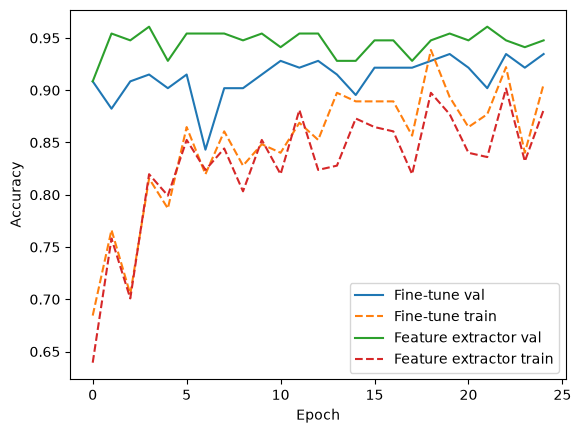

In [5]:
import matplotlib.pyplot as plt
for n, h in [("Fine-tune", hist_ft), ("Feature extractor", hist_fe)]:
    plt.plot(h['val'], label=f"{n} val"); plt.plot(h['train'], '--', label=f"{n} train")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.show()